# Original work

In [ ]:
# Imports for EDA
import pandas as pd
import matplotlib as plt
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Splitting and Normalization
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split

# Libraries for Error Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.metrics import f1_score

# Model
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import LabelEncoder

# Permutation Testing and Partial Dependence
from sklearn.inspection import permutation_importance
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
!pip install pulp
!pip install pycebox
from pycebox.ice import ice, ice_plot


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 41.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for pycebox: filename=pycebox-0.0.1-py3-none-any.whl size=3624 sha256=994b1fb633153b64ac93475626d35d72b8ae59f31c51df74ef65fd364ff1a323
  Stored in directory: /root/.cache/pip/wheels/15/ca/f5/deca7e8682d7eb6f9a948e62bec0f417baa046779b1c54ef52
Successfully built pycebox


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Data Import

In [ ]:
# importing all the csv files & whatever was given from Professor

y_train = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/y_train.csv')
y_test = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/y_test.csv')
x_train = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/X_train.csv')
x_test = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/X_test.csv')
complaints = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/complaints.csv')
df_sample = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/df_sample.csv')


<ipython-input-3-30bc85d6ac94>:7: DtypeWarning: Columns (16) have mixed types. Specify dtype option on import or set low_memory=False.
  complaints = pd.read_csv('/content/drive/MyDrive/DL Spring 2025 project/complaints.csv')


In [ ]:
x_test_copy = x_test.copy()

In [ ]:
y_train.head()

,company_response_to_consumer
0,Closed with explanation
1,Closed with non-monetary relief
2,Closed with non-monetary relief
3,Closed with explanation
4,Closed with explanation


In [ ]:
y_test.head()

,company_response_to_consumer
0,Closed with explanation
1,Closed with non-monetary relief
2,Closed with explanation
3,Closed with explanation
4,Closed with non-monetary relief


In [ ]:
x_train.head()

,date_received,product,sub-product,issue,sub-issue,consumer_complaint_narrative,company_public_response,company,state,zip_code,tags,consumer_consent_provided?,submitted_via,date_sent_to_company,timely_response?,consumer_disputed?,complaint_id,narrative_length
0,2024-04-01,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Credit inquiries on your report that you don't...,"TransUnion, XXXX, & XXXX are reporting inquiri...",Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",TX,77084,NaN,Consent provided,Web,2024-04-01,Yes,NaN,8670881,72
1,2018-03-12,"Credit reporting, credit repair services, or o...",Credit reporting,Improper use of your report,Reporting company used your report improperly,XXXX XXXX XXXX is showing on my credit report ...,NaN,CL Holdings LLC,OH,45424,NaN,Consent provided,Web,2018-03-12,Yes,NaN,2839979,60
2,2024-04-24,Credit reporting or other personal consumer re...,Credit reporting,Problem with a company's investigation into an...,Investigation took more than 30 days,I am writing to express my concern regarding t...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",NY,11412,NaN,Consent provided,Web,2024-04-24,Yes,NaN,8846347,201
3,2023-06-10,"Credit reporting, credit repair services, or o...",Credit reporting,Problem with a credit reporting company's inve...,Problem with personal statement of dispute,My credit report shows a deduction in my credi...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",TX,77489,NaN,Consent provided,Web,2023-06-10,Yes,NaN,7099297,30
4,2023-01-23,Mortgage,Conventional home mortgage,Trouble during payment process,NaN,"Hi, my name is XXXX XXXX and I had Wells Fargo...",Company has responded to the consumer and the ...,WELLS FARGO & COMPANY,MA,02151,NaN,Consent provided,Web,2023-01-23,Yes,NaN,6475670,36


In [ ]:
x_test.head()

,date_received,product,sub-product,issue,sub-issue,consumer_complaint_narrative,company_public_response,company,state,zip_code,tags,consumer_consent_provided?,submitted_via,date_sent_to_company,timely_response?,consumer_disputed?,complaint_id,narrative_length
0,2024-09-10,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Information belongs to someone else,"Upon reviewing my credit report, I have identi...",Company has responded to the consumer and the ...,Experian Information Solutions Inc.,TX,76133,NaN,Consent provided,Web,2024-09-10,Yes,NaN,10064586,18
1,2024-01-18,Credit reporting or other personal consumer re...,Credit reporting,Problem with a company's investigation into an...,Their investigation did not fix an error on yo...,I been trying to buy a car and it is causing m...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",IN,46321,NaN,Consent provided,Web,2024-01-18,Yes,NaN,8169121,87
2,2024-05-16,Credit reporting or other personal consumer re...,Credit reporting,Improper use of your report,Report provided to employer without your writt...,Received a warning that 8 different unauthoriz...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",MA,018XX,NaN,Consent provided,Web,2024-05-16,Yes,NaN,9028636,38
3,2017-09-28,Credit card or prepaid card,General-purpose credit card or charge card,"Advertising and marketing, including promotion...",Didn't receive advertised or promotional terms,I applied for a Citi/AAdvantage Platinum Selec...,Company has responded to the consumer and the ...,"CITIBANK, N.A.",VA,222XX,Older American,Consent provided,Web,2017-09-28,Yes,NaN,2687121,186
4,2024-07-12,Credit reporting or other personal consumer re...,Credit reporting,Incorrect information on your report,Account status incorrect,I am writing to formally dispute inaccurate in...,Company has responded to the consumer and the ...,"TRANSUNION INTERMEDIATE HOLDINGS, INC.",FL,32209,NaN,Consent provided,Web,2024-07-12,Yes,NaN,9488151,188


In [ ]:
print(y_train.value_counts())
print(y_test.value_counts())
print(x_train.value_counts())
print(x_test.value_counts())
print(complaints.value_counts())
print(df_sample.value_counts())

company_response_to_consumer   
Closed with explanation            53766
Closed with non-monetary relief    23073
Closed with monetary relief         2336
In progress                          539
Untimely response                    172
Closed                               114
Name: count, dtype: int64
company_response_to_consumer   
Closed with explanation            13442
Closed with non-monetary relief     5769
Closed with monetary relief          584
In progress                          135
Untimely response                     43
Closed                                28
Name: count, dtype: int64
date_received  product          sub-product                            issue                                  sub-issue                             consumer_complaint_narrative                                                                                                                                                                                                                        

# Data Prep
All students will use this dataset for X_train, X_test, y_train, y_test. Download your own copy of the data ASAP so that there are no issues.

# 100k sample

In [ ]:
'''
# prompt: unzip this file /content/drive/MyDrive/Research/DL Spring 2025 project/complaints.csv.zip

import zipfile
import os

zip_path = '/content/drive/MyDrive/Research/DL Spring 2025 project/complaints.csv.zip'
extract_path = '/content/drive/MyDrive/Research/DL Spring 2025 project/'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print(f"File unzipped to: {extract_path}")
'''


'\n# prompt: unzip this file /content/drive/MyDrive/Research/DL Spring 2025 project/complaints.csv.zip\n\nimport zipfile\nimport os\n\nzip_path = \'/content/drive/MyDrive/Research/DL Spring 2025 project/complaints.csv.zip\'\nextract_path = \'/content/drive/MyDrive/Research/DL Spring 2025 project/\'\n\nwith zipfile.ZipFile(zip_path, \'r\') as zip_ref:\n    zip_ref.extractall(extract_path)\n\nprint(f"File unzipped to: {extract_path}")\n'

Target class distribution (before sampling):
company_response_to_consumer
Closed with explanation            1776088
Closed with non-monetary relief     762187
Closed with monetary relief          77162
In progress                          17803
Untimely response                     5684
Closed                                3741
Name: count, dtype: int64


<ipython-input-11-0a77f81e6a18>:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_sample = df_filtered.groupby(target_col, group_keys=False).apply(lambda x: x.sample(frac=frac, random_state=42))


Saved sample to cfpb_clean_100k.csv


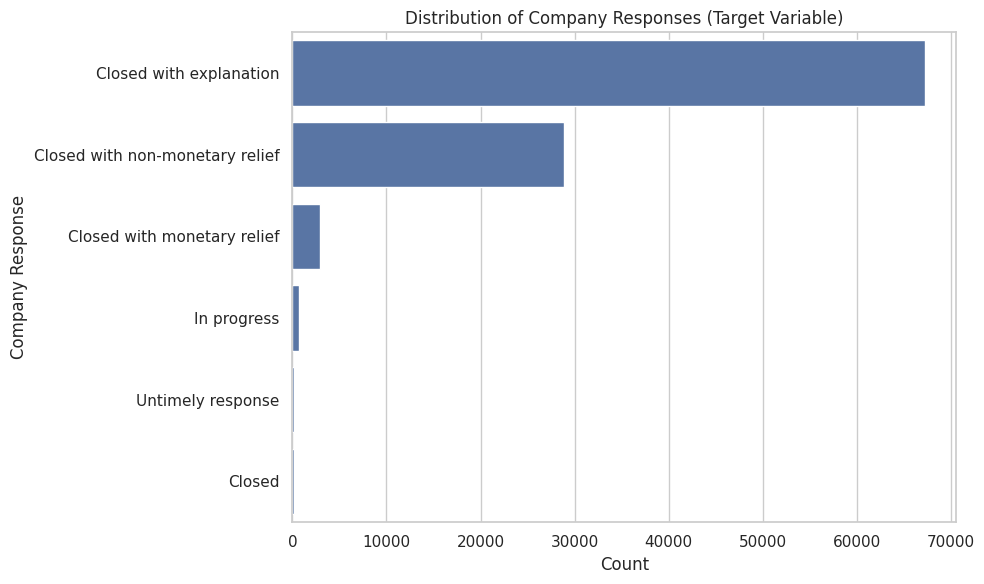

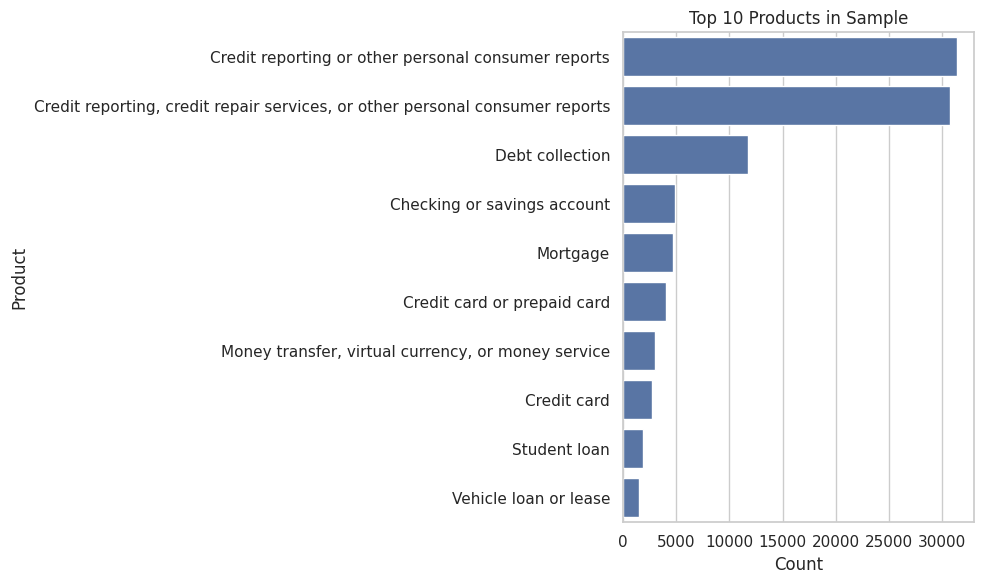

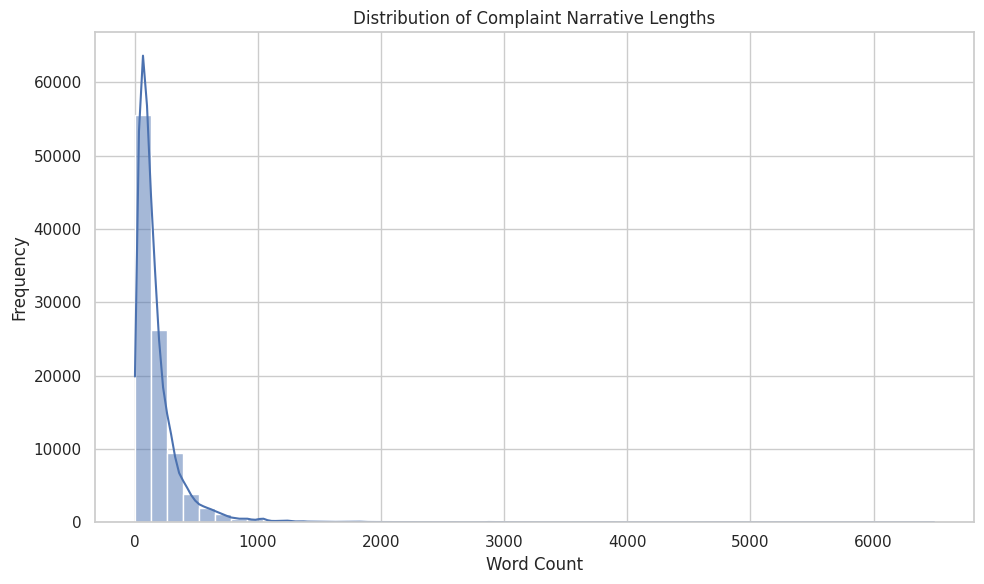

In [ ]:
# CFPB Consumer Complaints - 100K Sample Prep Notebook

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

# Set display options
pd.set_option('display.max_columns', 100)

# === 1. Load Full Dataset ===
#file_path = "/content/drive/MyDrive/Research/DL Spring 2025 project/complaints.csv"  # Update this path if needed#
#df = pd.read_csv(file_path, low_memory=False)
df = complaints

# === 2. Standardize Column Names ===
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# === 3. Filter for Clean Narratives and Target ===
target_col = 'company_response_to_consumer'
text_col = 'consumer_complaint_narrative'

# Drop rows missing either target or text
df_filtered = df[
    df[text_col].notnull() &
    df[target_col].notnull()
].copy()

# Print class distribution
print("Target class distribution (before sampling):")
print(df_filtered[target_col].value_counts())

# === 4. Sample 100K Rows (Stratified) ===
frac = min(1.0, 100000 / len(df_filtered))
df_sample = df_filtered.groupby(target_col, group_keys=False).apply(lambda x: x.sample(frac=frac, random_state=42))

# === 5. Export Clean Sample ===
output_path = "cfpb_clean_100k.csv"
df_sample.to_csv(output_path, index=False)
print(f"Saved sample to {output_path}")

# === 6. Basic EDA ===
sns.set(style="whitegrid")

# Plot class distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df_sample, y=target_col, order=df_sample[target_col].value_counts().index)
plt.title("Distribution of Company Responses (Target Variable)")
plt.xlabel("Count")
plt.ylabel("Company Response")
plt.tight_layout()
plt.show()

# Plot most common products
plt.figure(figsize=(10, 6))
top_products = df_sample['product'].value_counts().head(10)
sns.barplot(y=top_products.index, x=top_products.values)
plt.title("Top 10 Products in Sample")
plt.xlabel("Count")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

# Plot complaint length distribution
df_sample['narrative_length'] = df_sample[text_col].apply(lambda x: len(re.findall(r'\w+', str(x))))
plt.figure(figsize=(10, 6))
sns.histplot(df_sample['narrative_length'], bins=50, kde=True)
plt.title("Distribution of Complaint Narrative Lengths")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


Instructed to use provided x_train, x_test, y_train, y_test CSV files (Commented Out section below)

In [ ]:
'''
# prompt: split into train and test partitions

from sklearn.model_selection import train_test_split

# Assuming 'df_sample' is your DataFrame and 'target_col' is the column with target labels
X = df_sample.drop(columns=[target_col])  # Features (everything except the target)
y = df_sample[target_col]  # Target variable

# Split data into train and test sets (e.g., 80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Print the shapes of the resulting sets
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
'''


'\n# prompt: split into train and test partitions\n\nfrom sklearn.model_selection import train_test_split\n\n# Assuming \'df_sample\' is your DataFrame and \'target_col\' is the column with target labels\nX = df_sample.drop(columns=[target_col])  # Features (everything except the target)\ny = df_sample[target_col]  # Target variable\n\n# Split data into train and test sets (e.g., 80% train, 20% test)\nX_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)\n\n# Print the shapes of the resulting sets\nprint(f"X_train shape: {X_train.shape}")\nprint(f"X_test shape: {X_test.shape}")\nprint(f"y_train shape: {y_train.shape}")\nprint(f"y_test shape: {y_test.shape}")\n'

In [ ]:
y_train.value_counts()

,count
company_response_to_consumer,
Closed with explanation,53766
Closed with non-monetary relief,23073
Closed with monetary relief,2336
In progress,539
Untimely response,172
Closed,114


In [ ]:
y_test.value_counts()

,count
company_response_to_consumer,
Closed with explanation,13442
Closed with non-monetary relief,5769
Closed with monetary relief,584
In progress,135
Untimely response,43
Closed,28


#### EDA/Feature Engineering

##### Converting Dates to Seasons (Time of Year) - Column Dropped in Final Model

In [ ]:
x_test["date_received"] = pd.to_datetime(x_test["date_received"])
x_test["date_sent_to_company"] = pd.to_datetime(x_test["date_sent_to_company"])

In [ ]:
def add_season_column(df, date_col, season_col="season_date_received"):
    # ensure the date column is datetime
    df[date_col] = pd.to_datetime(df[date_col])

    # mapping month -> season
    season_map = {
        1: "winter", 2: "winter", 12: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "fall",   10: "fall",  11: "fall"
    }

    # map month numbers to season names
    df[season_col] = df[date_col].dt.month.map(season_map)
    return df

# Example usage:
df = pd.DataFrame({
    "signup_date": ["2025-01-15", "2025-04-22", "2025-08-03", "2025-11-10"]
})
x_test = add_season_column(x_test, "date_received")

def add_season_column(df, date_col, season_col="season_date_sent_to_company"):
    # ensure the date column is datetime
    df[date_col] = pd.to_datetime(df[date_col])

    # mapping month -> season
    season_map = {
        1: "winter", 2: "winter", 12: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "fall",   10: "fall",  11: "fall"
    }

    # map month numbers to season names
    df[season_col] = df[date_col].dt.month.map(season_map)
    return df

# Example usage:
df = pd.DataFrame({
    "signup_date": ["2025-01-15", "2025-04-22", "2025-08-03", "2025-11-10"]
})
x_test = add_season_column(x_test, "date_sent_to_company")

In [ ]:
x_train["date_received"] = pd.to_datetime(x_train["date_received"])
x_train["date_sent_to_company"] = pd.to_datetime(x_train["date_sent_to_company"])

In [ ]:
def add_season_column(df, date_col, season_col="season_date_received"):
    # ensure the date column is datetime
    df[date_col] = pd.to_datetime(df[date_col])

    # mapping month -> season
    season_map = {
        1: "winter", 2: "winter", 12: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "fall",   10: "fall",  11: "fall"
    }

    # map month numbers to season names
    df[season_col] = df[date_col].dt.month.map(season_map)
    return df

# Example usage:
df = pd.DataFrame({
    "signup_date": ["2025-01-15", "2025-04-22", "2025-08-03", "2025-11-10"]
})
x_train = add_season_column(x_train, "date_received")

def add_season_column(df, date_col, season_col="season_date_sent_to_company"):
    # ensure the date column is datetime
    df[date_col] = pd.to_datetime(df[date_col])

    # mapping month -> season
    season_map = {
        1: "winter", 2: "winter", 12: "winter",
        3: "spring", 4: "spring", 5: "spring",
        6: "summer", 7: "summer", 8: "summer",
        9: "fall",   10: "fall",  11: "fall"
    }

    # map month numbers to season names
    df[season_col] = df[date_col].dt.month.map(season_map)
    return df

# Example usage:
df = pd.DataFrame({
    "signup_date": ["2025-01-15", "2025-04-22", "2025-08-03", "2025-11-10"]
})
x_train = add_season_column(x_train, "date_sent_to_company")


##### Converting Public Statement where one is given 1 (yes), 0 (No)

In [ ]:
x_train['public_statement_flag'] = x_train['company_public_response'].notna().astype(int)

In [ ]:
x_test['public_statement_flag'] = x_test['company_public_response'].notna().astype(int)

##### Timely Response where one is given 1 (yes), 0 (No)

In [ ]:
x_train['timely_response_flag'] = x_train['timely_response?'].map({'Yes': 1, 'No': 0})

In [ ]:
x_test['timely_response_flag'] = x_test['timely_response?'].map({'Yes': 1, 'No': 0})

##### Consent Provided - Column Dropped in Final Model

In [ ]:
#x_train['consumer_consent_provided_flag'] = x_train['consumer_consent_provided?'].map({'Consent provided': 1, 'NaN': 0})

In [ ]:
#x_test['consumer_consent_provided_flag'] = x_test['consumer_consent_provided?'].map({'Consent provided': 1, 'NaN': 0})

##### Tags Provided

In [ ]:
x_train['tags_flag'] = x_train['tags'].notna().astype(int)

In [ ]:
x_test['tags_flag'] = x_test['tags'].notna().astype(int)

##### Credit Related

In [ ]:
x_train['credit_related_flag'] = x_train['product'].str.contains('credit', case=False, na=False).astype(int)
x_test['credit_related_flag'] = x_test['product'].str.contains('credit', case=False, na=False).astype(int)

##### Checking Related

In [ ]:
x_train['checking_related_flag'] = x_train['product'].str.contains('checking', case=False, na=False).astype(int)
x_test['checking_related_flag'] = x_test['product'].str.contains('checking', case=False, na=False).astype(int)

##### Loan Related

In [ ]:
x_train['loan_related_flag'] = x_train['product'].str.contains('loan', case=False, na=False).astype(int)
x_test['loan_related_flag'] = x_test['product'].str.contains('loan', case=False, na=False).astype(int)

##### Account Related

In [ ]:
x_train['account_related_flag'] = x_train['product'].str.contains('account', case=False, na=False).astype(int)
x_test['account_related_flag'] = x_test['product'].str.contains('account', case=False, na=False).astype(int)

##### Service Related

In [ ]:
x_train['service_related_flag'] = x_train['product'].str.contains('service', case=False, na=False).astype(int)
x_test['service_related_flag'] = x_test['product'].str.contains('service', case=False, na=False).astype(int)

##### Sub Product Mortage Related

In [ ]:
x_train['sub_product_mortgage_related_flag'] = x_train['sub-product'].str.contains('mortgage', case=False, na=False).astype(int)
x_test['sub_product_mortgage_related_flag'] = x_test['sub-product'].str.contains('mortgage', case=False, na=False).astype(int)

##### Sub Product Loan RELATYED

In [ ]:
x_train['sub_product_loan_related_flag'] = x_train['sub-product'].str.contains('loan', case=False, na=False).astype(int)
x_test['sub_product_loan_related_flag'] = x_test['sub-product'].str.contains('loan', case=False, na=False).astype(int)

##### Sub Product CD related - Column Dropped in Final Model

In [ ]:
#x_train['sub_product_cd_related_flag'] = x_train['sub-product'].str.contains('cd', case=False, na=False).astype(int)
#x_test['sub_product_cd_related_flag'] = x_test['sub-product'].str.contains('cd', case=False, na=False).astype(int)

##### Sub Product Auto Related - Column Dropped in Final Model


In [ ]:
#x_train['sub_product_auto_related_flag'] = x_train['sub-product'].str.contains('auto', case=False, na=False).astype(int)
#x_test['sub_product_auto_related_flag'] = x_test['sub-product'].str.contains('auto', case=False, na=False).astype(int)

##### Sub Product Credit Related


In [ ]:
x_train['sub_product_credit_related_flag'] = x_train['sub-product'].str.contains('credit', case=False, na=False).astype(int)
x_test['sub_product_credit_related_flag'] = x_test['sub-product'].str.contains('credit', case=False, na=False).astype(int)

##### Sub Product Debit Related - Column Dropped in Final Model


In [ ]:
#x_train['sub_product_debit_related_flag'] = x_train['sub-product'].str.contains('debit', case=False, na=False).astype(int)
#x_test['sub_product_debit_related_flag'] = x_test['sub-product'].str.contains('debit', case=False, na=False).astype(int)

##### Issues

##### Issue Contains Problem or Problems

In [ ]:
x_train['issue_problems_flag'] = x_train['issue'].str.contains('problem' or 'problems', case=False, na=False).astype(int)
x_test['issue_problems_flag'] = x_test['issue'].str.contains('problem' or 'problems', case=False, na=False).astype(int)


##### Issue Containds Fraud - Column Dropped in Final Model

In [ ]:
#x_train['issue_fraud_flag'] = x_train['issue'].str.contains('fraud', case=False, na=False).astype(int)
#x_test['issue_fraud_flag'] = x_test['issue'].str.contains('fraud', case=False, na=False).astype(int)


##### Issue Contains Credit

In [ ]:
x_train['issue_credit_flag'] = x_train['issue'].str.contains('credit', case=False, na=False).astype(int)
x_test['issue_credit_flag'] = x_test['issue'].str.contains('credit', case=False, na=False).astype(int)


##### Issue Contains Loan

In [ ]:
x_train['issue_loan_flag'] = x_train['issue'].str.contains('loan', case=False, na=False).astype(int)
x_test['issue_loan_flag'] = x_test['issue'].str.contains('loan', case=False, na=False).astype(int)

##### Issue Contains Unexpected - Column Dropped in Final Model

In [ ]:
#x_train['issue_unexpected_flag'] = x_train['issue'].str.contains('unexpected', case=False, na=False).astype(int)
#x_test['issue_unexpected_flag'] = x_test['issue'].str.contains('unexpected', case=False, na=False).astype(int)

##### Issue Contains Money - Column Dropped in Final Model

In [ ]:
#x_train['issue_money_flag'] = x_train['issue'].str.contains('money', case=False, na=False).astype(int)
#x_test['issue_money_flag'] = x_test['issue'].str.contains('money', case=False, na=False).astype(int)

##### Issue Contains Mortgage

In [ ]:
x_train['issue_mortgage_flag'] = x_train['issue'].str.contains('mortgage', case=False, na=False).astype(int)
x_test['issue_mortgage_flag'] = x_test['issue'].str.contains('mortgage', case=False, na=False).astype(int)

##### Issue Contains Account

In [ ]:
x_train['issue_account_flag'] = x_train['issue'].str.contains('account', case=False, na=False).astype(int)
x_test['issue_account_flag'] = x_test['issue'].str.contains('account', case=False, na=False).astype(int)

##### Issue Contains Bankruptcy - Column Dropped in Final Model

In [ ]:
#x_train['issue_bankruptcy_flag'] = x_train['issue'].str.contains('bankruptcy', case=False, na=False).astype(int)
#x_test['issue_bankruptcy_flag'] = x_test['issue'].str.contains('bankruptcy', case=False, na=False).astype(int)

##### Issue Contains Unauthorized - Column Dropped in Final Model

In [ ]:
#x_train['issue_unauthorized_flag'] = x_train['issue'].str.contains('unauthorized', case=False, na=False).astype(int)
#x_test['issue_unauthorized_flag'] = x_test['issue'].str.contains('unauthorized', case=False, na=False).astype(int)

##### Creating Dummy Variables for Season when complaint was received - Column Dropped in Final Model

In [ ]:
'''cat_cols = ['season_date_received']

for col in cat_cols:
    # Apply get_dummies to x_train instead of df
    dummies = pd.get_dummies(x_train[col], prefix=col, drop_first=False, dtype=int)
    x_train = pd.concat([x_train, dummies], axis=1)
'''

"cat_cols = ['season_date_received']\n\nfor col in cat_cols:\n    # Apply get_dummies to x_train instead of df\n    dummies = pd.get_dummies(x_train[col], prefix=col, drop_first=False, dtype=int)\n    x_train = pd.concat([x_train, dummies], axis=1)\n"

In [ ]:
'''cat_cols = ['season_date_received']

for col in cat_cols:
    # Apply get_dummies to x_train instead of df
    dummies = pd.get_dummies(x_test[col], prefix=col, drop_first=False, dtype=int)
    x_test = pd.concat([x_test, dummies], axis=1)
'''

"cat_cols = ['season_date_received']\n\nfor col in cat_cols:\n    # Apply get_dummies to x_train instead of df\n    dummies = pd.get_dummies(x_test[col], prefix=col, drop_first=False, dtype=int)\n    x_test = pd.concat([x_test, dummies], axis=1)\n"

#### Plots

##### Plot 1 - Distribution of Target Classes

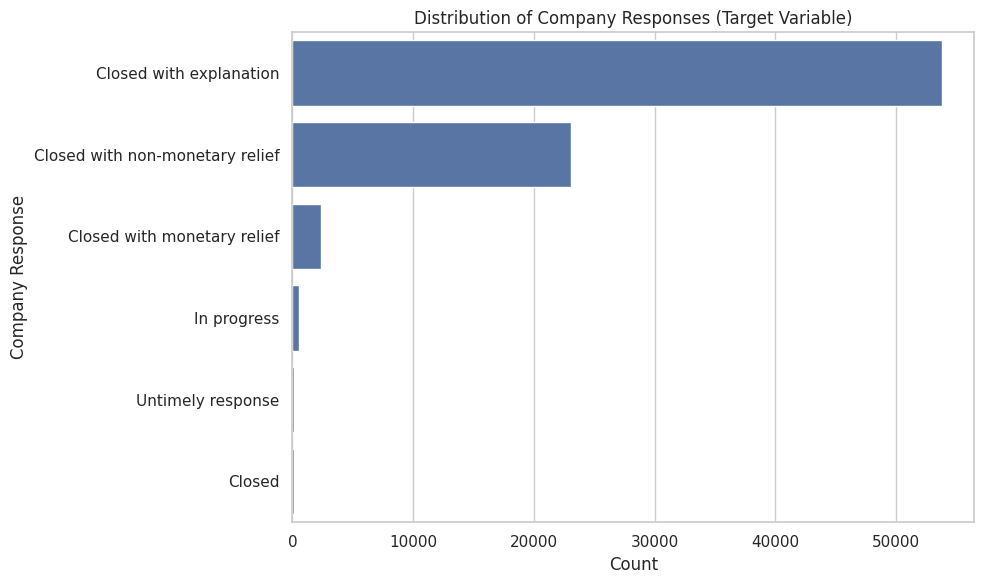

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(y=y_train.iloc[:, 0], order=y_train.iloc[:, 0].value_counts().index)
plt.title("Distribution of Company Responses (Target Variable)")
plt.xlabel("Count")
plt.ylabel("Company Response")
plt.tight_layout()
plt.show()

In Plot 1, Distribution of Company Responses (Target Variable), you can see the general outcome of company responses within the training set. You can see the large majority of the distribution falls in the "Closed with Explanation" company response. Over 50,000 match this criteria, while the next highest shows ~25,000 for "Closed with non-monetary relief". The remaining results shows all under 2,500 company responses. This is critical information in a dataset like this because it is massive. Being able to pinpoint the data into groups and actively distinguish where the majority lies will be important in guiding us to our solutions we seek.

##### Plot 2 - Top 10 Products

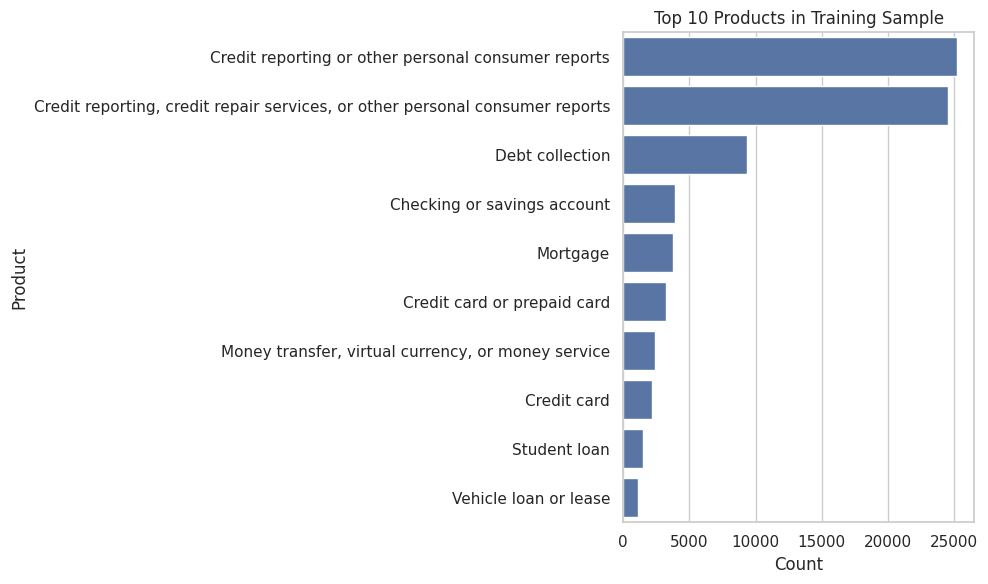

In [ ]:

plt.figure(figsize=(10, 6))
top_products = x_train['product'].value_counts().head(10)
sns.barplot(y=top_products.index, x=top_products.values)
plt.title("Top 10 Products in Training Sample")
plt.xlabel("Count")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In Plot 2, you can see the top products within our training sample. Similar to Plot 1, there were two main categories - Credit reporting or other personal consumer reports, and Credit reporting, credit repair services, or toher personal consumer reports. These two were each around 25,000 outputs, while debt collection, checking or savings account, mortgage, and others fell below 10,000. This is another critical plot because it provides deeper insight into what type of product issue categories they were in. This way, we can bin and focus on groups for each type of problem!

##### Plot 3 - Add narrative_length to X_train and X_test

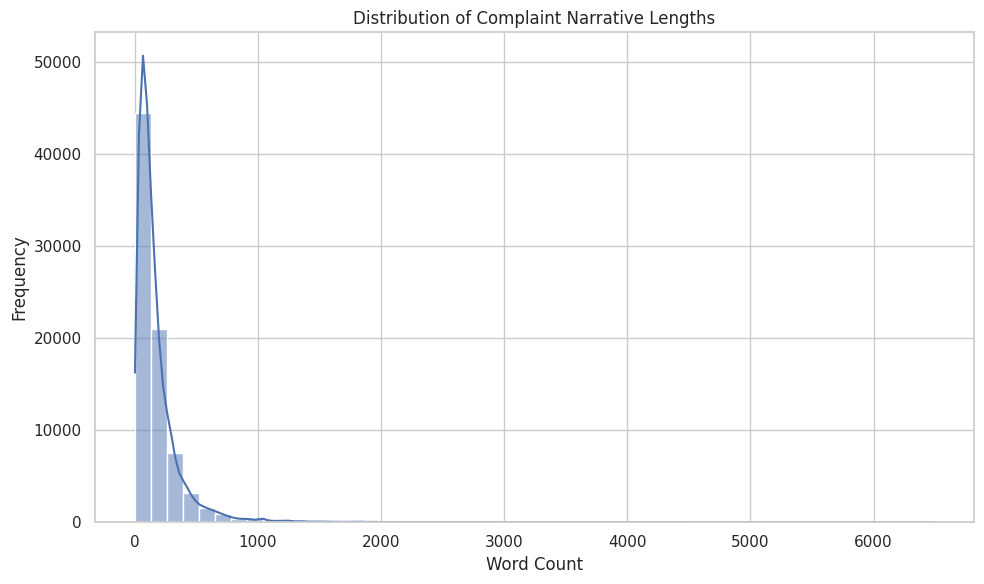

In [ ]:

x_train_tmp = x_train.copy()
x_test_tmp = x_test.copy()

x_train_tmp['narrative_length'] = x_train_tmp['consumer_complaint_narrative'].apply(lambda x: len(re.findall(r'\w+', str(x))))
x_test_tmp['narrative_length'] = x_test_tmp['consumer_complaint_narrative'].apply(lambda x: len(re.findall(r'\w+', str(x))))

# Plot 3: Narrative length distribution
plt.figure(figsize=(10, 6))
sns.histplot(x_train_tmp['narrative_length'], bins=50, kde=True)
plt.title("Distribution of Complaint Narrative Lengths")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In Plot 3, we are overviewing the distribution of the length of each complaint narrative. This is essentially how long the complaint is, which could help determine a few things to focus on. One idea that came to mind was: do longer messages result in better results for the customer/person complaining? There is a good amount of results around the range of 0 and 200 words, but there are some that trickle into around 1,000 words. Seeing a 1,000 word complaint can be incredibly in depth and serious, which would be important for a company to follow and understand.

##### Plot 4 - Box Plot of Narrative Length by Response Type

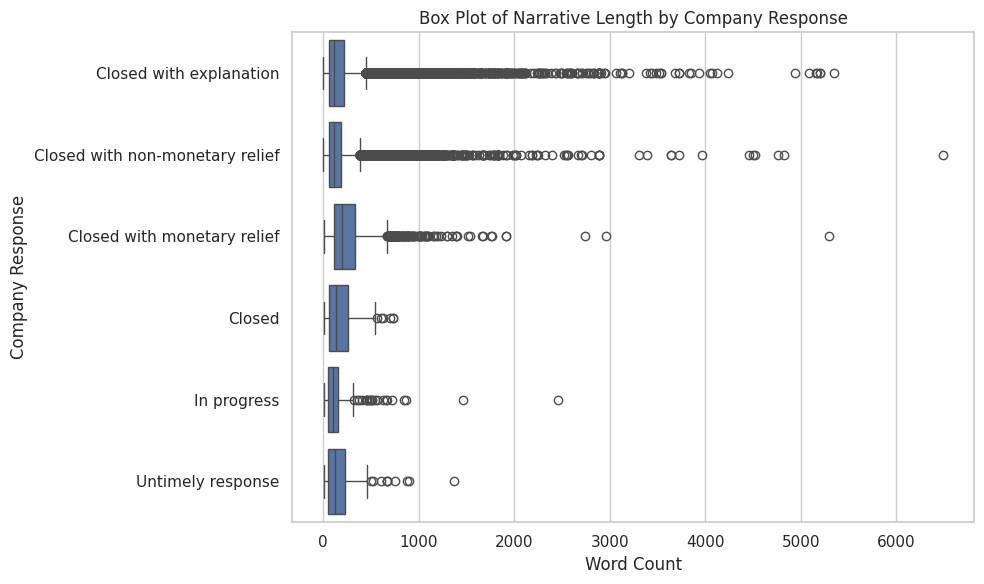

In [ ]:

train_data = x_train.copy()
train_data['target'] = y_train

# Plot box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=train_data, x='narrative_length', y='target')
plt.title("Box Plot of Narrative Length by Company Response")
plt.xlabel("Word Count")
plt.ylabel("Company Response")
plt.tight_layout()
plt.show()

Plot 4 shows a box plot of the trends we see with the length of the complaint based on the type of company response. The main trend we observed with this and arguably most important is that Closed with monetary relief tends to have a longer narrative in comparison to others. With saying this, the general population for this falls in a large chunk between 750 and 1,250 words. In Closed with explanation, you can see the range is much spread out along the word count spreader.

##### Plot 5 - Count of Issues by Season and Public Statement Made

<Figure size 1200x500 with 0 Axes>

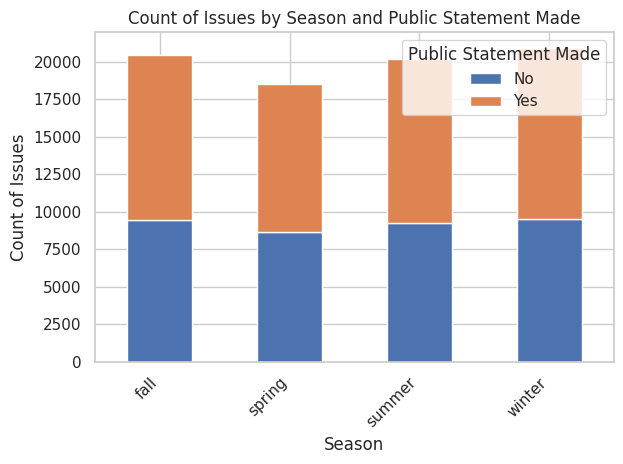

In [ ]:
x_train_tmp = x_train.copy()
x_train_tmp['public_statement'] = np.where(x_train['company_public_response'].isna(), 'No', 'Yes')
counts = x_train_tmp.groupby(['season_date_received', 'public_statement']).size().unstack(fill_value=0)

plt.figure(figsize=(12, 5))
counts.plot(kind='bar', stacked=True)
plt.xticks(rotation=45, ha='right')
plt.xlabel('Season')
plt.ylabel('Count of Issues')
plt.title('Count of Issues by Season and Public Statement Made')
plt.legend(title='Public Statement Made')
plt.tight_layout()
plt.show()

Our final plot, we look into the count of issues based on season and if a public statement was made. You can see each season is pretty evenly distributed, with Spring having the least amount of activity, but not by much. Each season gets around 9,000 No's and the remaining 10-11,000 are Yes's.

#### Tables

##### Table 1 - Top 10 Companies by Complaint Count

In [ ]:
print("Table 1: Top 10 Companies by Complaint Count")
print(x_train['company'].value_counts().head(10))

Table 1: Top 10 Companies by Complaint Count
company
TRANSUNION INTERMEDIATE HOLDINGS, INC.    15750
EQUIFAX, INC.                             15599
Experian Information Solutions Inc.       14786
CAPITAL ONE FINANCIAL CORPORATION          1623
WELLS FARGO & COMPANY                      1527
BANK OF AMERICA, NATIONAL ASSOCIATION      1460
JPMORGAN CHASE & CO.                       1439
CITIBANK, N.A.                             1338
SYNCHRONY FINANCIAL                         827
Block, Inc.                                 763
Name: count, dtype: int64


Our first table shows the companies with the highest complaint counts. You can see from the results that Tranunion Intermediate Holdings Inc. was the highest at 15,750. Equifax Inc. and Experian Information Systems were close second and third place candidate, and then fourth etc. all fell below 2,000 complaints. This would help explain a lot for our data and is extremely supportive. It can help identify a few things like which companies should be looked more in depth, or what companies we are getting the most feedback from.

##### Table 2 - Top 10 Issues by Complaint Count

In [ ]:
print("Table 2: Top 10 Issues by Complaint Count")
print(x_train['issue'].value_counts().head(10))

Table 2: Top 10 Issues by Complaint Count
issue
Incorrect information on your report                                                23098
Improper use of your report                                                         12667
Problem with a credit reporting company's investigation into an existing problem     7550
Problem with a company's investigation into an existing problem                      6087
Attempts to collect debt not owed                                                    3884
Managing an account                                                                  2073
Written notification about debt                                                      1774
Trouble during payment process                                                       1369
Problem with a purchase shown on your statement                                      1128
Other transaction problem                                                            1124
Name: count, dtype: int64


Table 2 provides information that can be easily affiliated with Table 1. The top issues by complaint count resulted in the most coming from a complaint titled "Incorrect information on your report". This had the majority at 23,000, while the next, Improper use of your report at almost 13,000, and the remainder less than 8,000. This helps companies understand where the majority of the issues derive from and allow them to focus more on these areas of the company. This will bring dramatic change in customer satisfaction.

##### Table 3 - Missing Value Summary (Percentage)

In [ ]:
print("Table 3: Missing Value Summary (Percentage)")
print((x_train.isnull().mean() * 100).round(2))

Table 3: Missing Value Summary (Percentage)
date_received                         0.00
product                               0.00
sub-product                           2.04
issue                                 0.00
sub-issue                            10.38
consumer_complaint_narrative          0.00
company_public_response              46.06
company                               0.00
state                                 0.38
zip_code                              0.00
tags                                 89.23
consumer_consent_provided?            0.00
submitted_via                         0.00
date_sent_to_company                  0.00
timely_response?                      0.00
consumer_disputed?                   93.70
complaint_id                          0.00
narrative_length                      0.00
season_date_received                  0.00
season_date_sent_to_company           0.00
public_statement_flag                 0.00
timely_response_flag                  0.00
tags_flag 

Table 3 shows what percentage of values contribute to the number of missing values in our data. The general population of variables have no missing values, but you can see that almost 93% of the variables in the customer_disputed tab are missing. A missing value in this could potentially indicate a "No" answer, as in when the answer is "Yes" you will see this but if it's "No" then it is left blank. This is helpful when cleaning our data and making it as accurate as possible.

##### Table 4 - Timely Response Summary

In [ ]:
timely_response_table = x_train['timely_response?'].value_counts()
timely_response_percentage = x_train['timely_response?'].value_counts(normalize=True) * 100

# Combine into one table
timely_response_summary = pd.DataFrame({
    'Count': timely_response_table,
    'Percentage': timely_response_percentage.round(2)
})
print(timely_response_summary)

                  Count  Percentage
timely_response?                   
Yes               79070       98.84
No                  930        1.16


In Table 4, you can see calculated the count of timely responses and what percentage of these each were. In this case, almost 99% of the responses were done in a timely manner, while 1.16% were not. This can help us solve a simple issue with some companies that just aren't answering the complaints. This can potentially help reduce the number of complaints we see because if they aren't done in a timely fashion this can bring additional complaints related to that one original issue. This would be helpful in finding a simple solution to this complex set of data.

##### Table 5 - Complaint Count by State

In [ ]:
complaints_by_state = x_train['state'].value_counts().head(10)
print(complaints_by_state)

state
FL    9564
TX    9278
CA    8751
GA    5707
NY    4831
IL    3806
PA    3291
NC    2906
NJ    2699
VA    2029
Name: count, dtype: int64


In our last table, we counted the number of complaints by location. This is looking at the locations with the greatest amount of complaints (top 10). You can see Florida, Texas, and California are the states with the greatest total amounts, all over 8,700. This is important to know because we can determine if there are specific companies that are weighing on this subject and address them right away, similar to a "taking down the big dog" approach. Once we find the companies with large amounts of complaints, we can deduct these states total number of complaints significantly.

### Models

##### Dropping String Fields

In [ ]:
x_train = x_train.drop(columns=['date_received', 'date_sent_to_company', 'company_public_response', 'timely_response?', 'consumer_consent_provided?', 'tags', 'consumer_disputed?'])

In [ ]:
x_test = x_test.drop(columns=['date_received', 'date_sent_to_company', 'company_public_response', 'timely_response?', 'consumer_consent_provided?', 'tags', 'consumer_disputed?'])

In [ ]:
x_train = x_train.drop(columns=['zip_code', 'product', 'sub-product', 'issue', 'state', 'sub-issue', 'consumer_complaint_narrative', 'company', 'submitted_via', 'complaint_id', 'season_date_sent_to_company', 'season_date_received'])

In [ ]:
x_test = x_test.drop(columns=['zip_code', 'product', 'sub-product', 'issue', 'state', 'sub-issue', 'consumer_complaint_narrative', 'company', 'submitted_via', 'complaint_id', 'season_date_sent_to_company', 'season_date_received'])

In [ ]:
print(x_train.shape)
print(x_test.shape)

(80000, 17)
(20001, 17)


In [ ]:
x_train.head(1)

,narrative_length,public_statement_flag,timely_response_flag,tags_flag,credit_related_flag,checking_related_flag,loan_related_flag,account_related_flag,service_related_flag,sub_product_mortgage_related_flag,sub_product_loan_related_flag,sub_product_credit_related_flag,issue_problems_flag,issue_credit_flag,issue_loan_flag,issue_mortgage_flag,issue_account_flag
0,72,1,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0


In [ ]:
x_train.dtypes

,0
narrative_length,int64
public_statement_flag,int64
timely_response_flag,int64
tags_flag,int64
credit_related_flag,int64
checking_related_flag,int64
loan_related_flag,int64
account_related_flag,int64
service_related_flag,int64
sub_product_mortgage_related_flag,int64


In [ ]:
print(type(x_train))
null_counts = x_train.isnull().sum()
print(null_counts[null_counts > 0])

<class 'pandas.core.frame.DataFrame'>
Series([], dtype: int64)


In [ ]:
print(type(x_test))
null_counts = x_test.isnull().sum()
print(null_counts[null_counts > 0])

<class 'pandas.core.frame.DataFrame'>
Series([], dtype: int64)


##### Model Building

In [ ]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)


/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.11/dist-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


In [ ]:
x_train.shape

(80000, 17)

In [ ]:
x_test.shape

(20001, 17)

In [ ]:
y_train.shape

(80000,)

In [ ]:
y_test.shape

(20001,)

In [ ]:
x_text_copy = x_test.copy()

In [ ]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [ ]:
boost = HistGradientBoostingClassifier(random_state=5)
boost = boost.fit(x_train, y_train)
y_pred = boost.predict(x_test)


In [ ]:
train_pred = boost.predict(x_train)
test_pred = boost.predict(x_test)

In [ ]:
print(le.classes_)

['Closed' 'Closed with explanation' 'Closed with monetary relief'
 'Closed with non-monetary relief' 'In progress' 'Untimely response']


In [ ]:
print(classification_report(y_train, train_pred))
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.03      0.03      0.03       114
           1       0.68      0.98      0.80     53766
           2       0.10      0.00      0.01      2336
           3       0.57      0.04      0.08     23073
           4       0.00      0.00      0.00       539
           5       0.28      0.38      0.32       172

    accuracy                           0.67     80000
   macro avg       0.28      0.24      0.21     80000
weighted avg       0.62      0.67      0.56     80000

              precision    recall  f1-score   support

           0       0.00      0.00      0.00        28
           1       0.68      0.98      0.80     13442
           2       0.06      0.00      0.00       584
           3       0.55      0.04      0.08      5769
           4       0.00      0.00      0.00       135
           5       0.10      0.14      0.12        43

    accuracy                           0.67     20001
   macro avg       0.23

/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/m

In [ ]:
print(confusion_matrix(y_train, train_pred))

[[    3   103     2     0     0     6]
 [   90 52746    57   728     0   145]
 [    7  2298     7    14     0    10]
 [    3 22068     3   990     0     9]
 [    0   538     0     1     0     0]
 [    5   100     1     0     0    66]]


In [ ]:
print(confusion_matrix(y_test, test_pred))

[[    0    27     0     0     0     1]
 [   27 13167    15   188     0    45]
 [    2   571     1     6     0     4]
 [    1  5523     0   240     0     5]
 [    0   135     0     0     0     0]
 [    0    36     1     0     0     6]]


###### Test Weighted F1 Score

In [ ]:
weighted_f1 = f1_score(y_test, test_pred, average='weighted')

In [ ]:
print(f"Weighted F1 = {weighted_f1:.4f}")

Weighted F1 = 0.5606


### Interprability

##### Permutation Importance

<ipython-input-84-9e71a4ed6139>:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax1.boxplot(result.importances[perm_sorted_idx].T, vert=False,


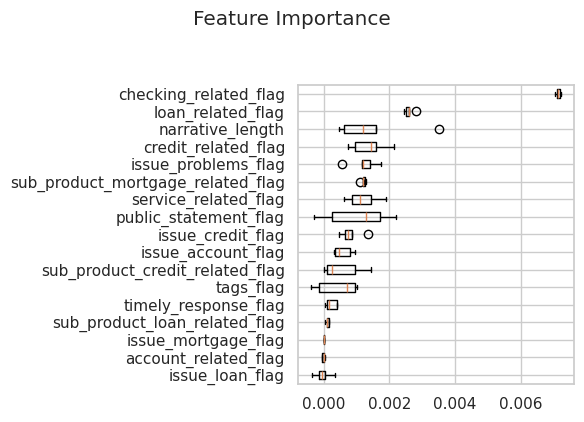

In [ ]:
clf = boost

feature_names = x_text_copy.columns.tolist()

result = permutation_importance(clf, x_test, y_test, n_repeats=5,
                                random_state=42)
perm_sorted_idx = result.importances_mean.argsort()

fig, ax1 = plt.subplots(1, 1, figsize=(6, 4))
ax1.boxplot(result.importances[perm_sorted_idx].T, vert=False,
            labels=np.array(feature_names)[perm_sorted_idx].tolist()) # Convert feature_names to a NumPy array for fancy indexing, then back to a list for labels
fig.suptitle('Feature Importance', y=1.05)
fig.tight_layout()
plt.show()

###### Top 5 Features


*   checking_related_flag
*   loan_related_flag
*   narrative_length
*   credit_related_flag
*   issue_problems_flag



##### Partial Dependence

###### Narrative Length

In [ ]:
train_X_df = pd.DataFrame(x_train, columns=feature_names)

In [ ]:
tmpdf = ice(data=train_X_df, # ice needs a dataframe
            column='narrative_length', # the column name
                   predict=boost.predict,
            num_grid_points=10) # the predict statement from the

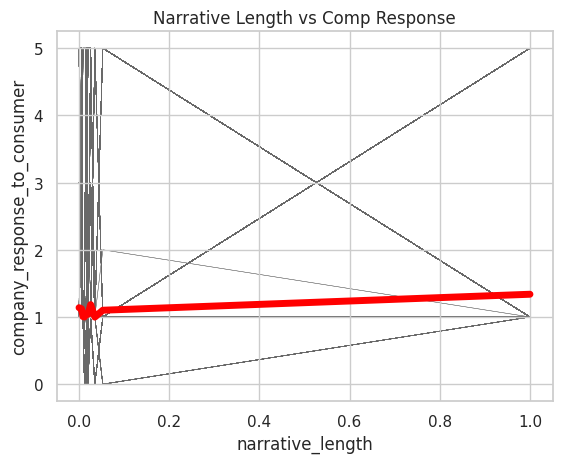

In [ ]:
ice_plot(tmpdf, c='dimgray', linewidth=0.3,
                  plot_pdp=True,
         pdp_kwargs={'linewidth': 5, 'color':'red'})
plt.title('Narrative Length vs Comp Response')
plt.ylabel('company_response_to_consumer')
plt.xlabel('narrative_length');
plt.show()

###### checking_related_flag

In [ ]:
train_X_df = pd.DataFrame(x_train, columns=feature_names)

In [ ]:
tmpdf = ice(data=train_X_df, # ice needs a dataframe
            column='checking_related_flag', # the column name
                   predict=boost.predict,
            num_grid_points=100) # the predict statement from the

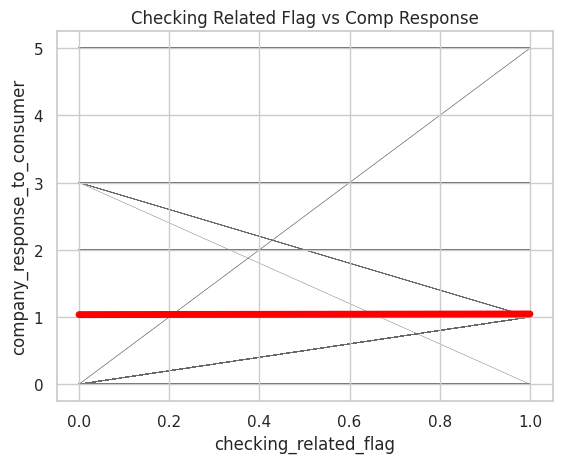

In [ ]:
ice_plot(tmpdf, c='dimgray', linewidth=0.3,
                  plot_pdp=True,
         pdp_kwargs={'linewidth': 5, 'color':'red'})
plt.title('Checking Related Flag vs Comp Response')
plt.ylabel('company_response_to_consumer')
plt.xlabel('checking_related_flag');
plt.show()

###### loan_related_flag

In [ ]:
train_X_df = pd.DataFrame(x_train, columns=feature_names)

In [ ]:
tmpdf = ice(data=train_X_df, # ice needs a dataframe
            column='loan_related_flag', # the column name
                   predict=boost.predict,
            num_grid_points=100) # the predict statement from the

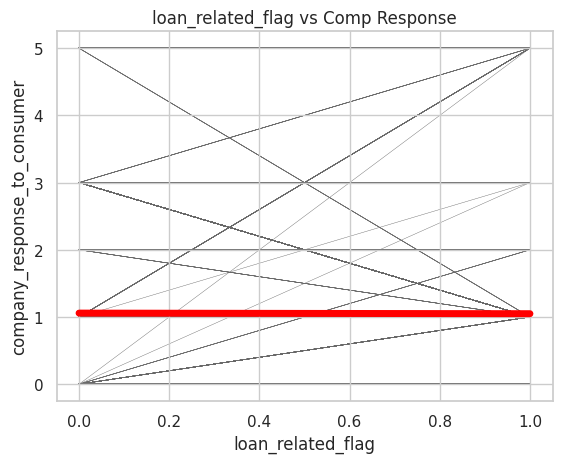

In [ ]:
ice_plot(tmpdf, c='dimgray', linewidth=0.3,
                  plot_pdp=True,
         pdp_kwargs={'linewidth': 5, 'color':'red'})
plt.title('loan_related_flag vs Comp Response')
plt.ylabel('company_response_to_consumer')
plt.xlabel('loan_related_flag');
plt.show()

###### credit_related_flag

In [ ]:
train_X_df = pd.DataFrame(x_train, columns=feature_names)

In [ ]:
tmpdf = ice(data=train_X_df, # ice needs a dataframe
            column='credit_related_flag', # the column name
                   predict=boost.predict,
            num_grid_points=100) # the predict statement from the

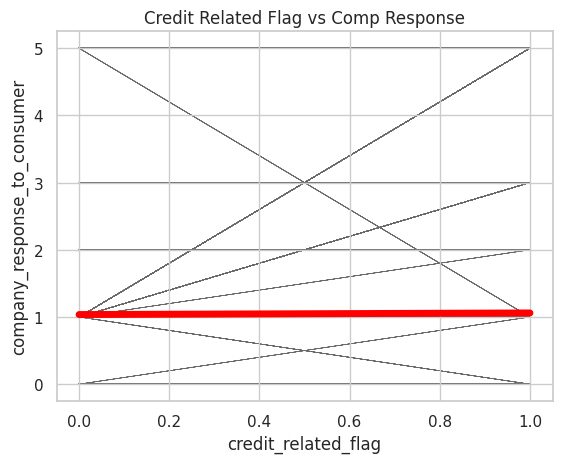

In [ ]:
ice_plot(tmpdf, c='dimgray', linewidth=0.3,
                  plot_pdp=True,
         pdp_kwargs={'linewidth': 5, 'color':'red'})
plt.title('Credit Related Flag vs Comp Response')
plt.ylabel('company_response_to_consumer')
plt.xlabel('credit_related_flag');
plt.show()

###### issue_problems_flag

In [ ]:
train_X_df = pd.DataFrame(x_train, columns=feature_names)

In [ ]:
tmpdf = ice(data=train_X_df, # ice needs a dataframe
            column='issue_problems_flag', # the column name
                   predict=boost.predict,
            num_grid_points=100) # the predict statement from the

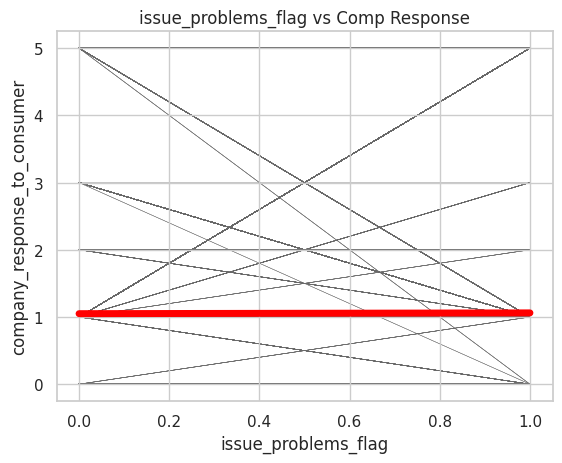

In [ ]:
ice_plot(tmpdf, c='dimgray', linewidth=0.3,
                  plot_pdp=True,
         pdp_kwargs={'linewidth': 5, 'color':'red'})
plt.title('issue_problems_flag vs Comp Response')
plt.ylabel('company_response_to_consumer')
plt.xlabel('issue_problems_flag');
plt.show()

# Discussion/Takeaways
Based on permutation importance of the model, the most important features for company response are features such as checking_related_flag, loan_related_flag, narrative_length, credit_related_flag, and issue_problems_flags. The flag features are used to indicate keywords from given problems, sub-problems, and issues. The narrative length represents the length of a given complaint.  



Based on the top 5 features our recommendation is filter product/sub products and issues/sub issues by key words also to consider the length of a give complaint to better suggest the best path for resolution when providing customers with a response.  

  

Narrative length suggests that customers who write longer complaints are more likely to be closed. We recommend having some sort of predefined form where customers are forced to provide all necessary data points to help drive closure of a claim. Narrative length can be a great predictor of prioritizing complaints. Overall, narrative length can prove worthy to companies because of the detail, thought, and opinion a customer will portray. The company can then more accurately diagnose the issue and provide better service to its customers.  

  

Even though the public statement flag was not a top 5 feature, we do advise that proactively issuing public responses in cases involving widespread/major issues would enable the company to reassure customers. This will aid in reducing the number of duplicate claims received for similar/related issues.  

   

Overall, for our model we began with creating many new fields such as converting dates to a given season and extracting key words from product, sub-products, and issues. However, we found that season and many of the key words extracted were insignificant and dropped from the final model.  

# Conclusion
This project proved to have it's adversity and sets of challenges, but overall we embraced a multitude of different skills and real world experiences using this dataset. Here are some of our main takeaways:

*   **Moving Step-by-step**: There were many moving parts to this project, and it was critical for us to move in unison with a progressive and efficient process flow. From prepping our data to ensuring we were using the correct datasets - there was always something we had to double or triple check.
*   **Time Consumption of Cleaning Data**: Whether EDA, meaningful plots/graphs, or feature engineering - this took time. This was one of the more challenging aspects of the project. We later learned that once this was completed everything flowed a lot smoother in the project. In the future, we would prioritize sitting down earlier in the project time frame to get the data cleaning out of the way.
*   **Attempting Different Models**: We were convoluded to begin in deciding where this project was going to take us. Because there were so many options to decide from in the Scikit Learning, and the methodologies we worked with in the class modules, it was difficult in deciding which suited best. This deemed extremely difficult for our group, but as a result of our critical thinking and discussions, our end results proved clear and effective.
*   **Class Flow with the project**: Our group can confidently say this project aligned very well with the course structure and what was covered throughout the 3-weeks. While strenuous, we assumed the project would guide us in the experimental direction and only in that direction. We were pleasantly to see the modeling and the interpretability aligned perfectly with what we were doing in homeworks and the midterm. It made this project much simpler to follow, comprehend, and enjoy!
*   **Trial-and-Error**: There were many instances as mentioned previously where we had to go back and sift through our work to ensure everything aligned with the next step. One thing we learned was how strong this team was in perseverance. Consistent trial and error led to eventual positive results!

